<a href="https://colab.research.google.com/github/nour2344/RoadAnomaly-DeepLearning/blob/main/notebooks/01_data_understanding.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# RoadAnomaly — Data Understanding

**Deep Learning Project | CRISP-DM — Phase 2**

## Project Overview

The objective of this project is to detect and localize unexpected obstacles in road scenes using Deep Learning and semantic segmentation.

This notebook focuses on understanding the RoadAnomaly dataset, exploring its characteristics, analyzing semantic annotations, and assessing data quality before preprocessing.

### Data Understanding Objectives

- Understand the dataset structure and available annotations.
- Analyze image dimensions and image-mask correspondence.
- Visualize original images and ground-truth masks.
- Study anomaly distribution and class imbalance.
- Explore different categories of road anomalies.
- Identify data quality issues and dataset limitations.

## 1. Dataset Loading

Load the RoadAnomaly dataset from Google Drive and identify the original images and their corresponding segmentation masks.

In [1]:

from google.colab import drive

drive.mount('/content/drive', force_remount=True)


Mounted at /content/drive


In [2]:

from pathlib import Path

# Chemin du dataset dans Google Drive
dataset_dir = Path(
    "/content/drive/MyDrive/deep learning P/RoadAnomaly"
)

print("Dataset exists:", dataset_dir.exists())

# Afficher le contenu du dossier
if dataset_dir.exists():
    for item in dataset_dir.iterdir():
        print(item.name)


Dataset exists: True
RoadAnomaly


In [3]:

# Chercher le dossier frames
frames_folders = [
    p for p in dataset_dir.rglob("frames")
    if p.is_dir()
]

print("Frames folders:", frames_folders)

if not frames_folders:
    raise FileNotFoundError("Dossier frames introuvable")

frames_dir = frames_folders[0]

print("Frames path:", frames_dir)

# Compter les images et les masques
images = list(frames_dir.glob("*.webp"))
masks = list(frames_dir.glob("*.labels/labels_semantic.png"))

print("Number of images:", len(images))
print("Number of masks:", len(masks))


Frames folders: [PosixPath('/content/drive/MyDrive/deep learning P/RoadAnomaly/RoadAnomaly/frames')]
Frames path: /content/drive/MyDrive/deep learning P/RoadAnomaly/RoadAnomaly/frames
Number of images: 60
Number of masks: 60


## 2. Dataset Description

Analyze the number of images, their dimensions, and the correspondence between images and semantic masks.

This step also examines the percentage of anomalous pixels in each image.

In [4]:

from PIL import Image
import numpy as np
import pandas as pd

records = []

for image_path in sorted(images):
    mask_path = (
        frames_dir / f"{image_path.stem}.labels"
        / "labels_semantic.png"
    )

    with Image.open(image_path) as img:
        width, height = img.size

    mask_exists = mask_path.exists()
    mask_aligned = False
    mask_values = []
    anomaly_percent = np.nan

    if mask_exists:
        with Image.open(mask_path) as m:
            mask = np.array(m)
            mask_aligned = m.size == (width, height)

        if mask.ndim == 2:
            mask_values = np.unique(mask).tolist()
            anomaly_percent = 100 * np.mean(mask == 2)

    records.append({
        "Image": image_path.name,
        "Width": width,
        "Height": height,
        "Mask_exists": mask_exists,
        "Mask_aligned": mask_aligned,
        "Mask_values": mask_values,
        "Anomaly_%": anomaly_percent
    })

df = pd.DataFrame(records)

print("Nombre d'images :", len(df))
print("Images avec masque :", df["Mask_exists"].sum())
print("Masques alignés :", df["Mask_aligned"].sum())

print("\nDimensions des images :")
print(df.groupby(["Width", "Height"]).size())

print("\nPourcentage moyen de pixels anormaux :")
print(df["Anomaly_%"].mean())

display(df.head(10))


Nombre d'images : 60
Images avec masque : 60
Masques alignés : 60

Dimensions des images :
Width  Height
1280   720       60
dtype: int64

Pourcentage moyen de pixels anormaux :
9.849560546875


,Image,Width,Height,Mask_exists,Mask_aligned,Mask_values,Anomaly_%
0,animals01_Guiguinto_railway_station_Calves.webp,1280,720,True,True,"[0, 2]",6.707574
1,animals02_Zagori_On_the_road_to_Papigko.webp,1280,720,True,True,"[0, 2]",0.799154
2,animals03_Zebras_in_the_road.webp,1280,720,True,True,"[0, 2]",23.374349
3,animals04_17_animal_casualties_so_far_in_2006....,1280,720,True,True,"[0, 2]",6.602105
4,animals05_cows_near_Phonsavan_Laos.webp,1280,720,True,True,"[0, 2]",14.610135
5,animals06_sheep_roads_lambs.webp,1280,720,True,True,"[0, 2]",36.845812
6,animals07_Aihole_Pattadakal.webp,1280,720,True,True,"[0, 2]",8.195530
7,animals08_on_the_main_street_of_village_Lin_Al...,1280,720,True,True,"[0, 2]",1.763346
8,animals09_working_together.webp,1280,720,True,True,"[0, 2]",42.328559
9,animals10_bovine_cattle_beside_road.webp,1280,720,True,True,"[0, 2]",2.773112


## 3. Data Visualization

Display an original road image, its ground-truth mask, and the overlay highlighting anomalous regions.

This visualization helps verify the accuracy and alignment of the annotations.

Image : animals01_Guiguinto_railway_station_Calves.webp
Valeurs du masque : [0 2]


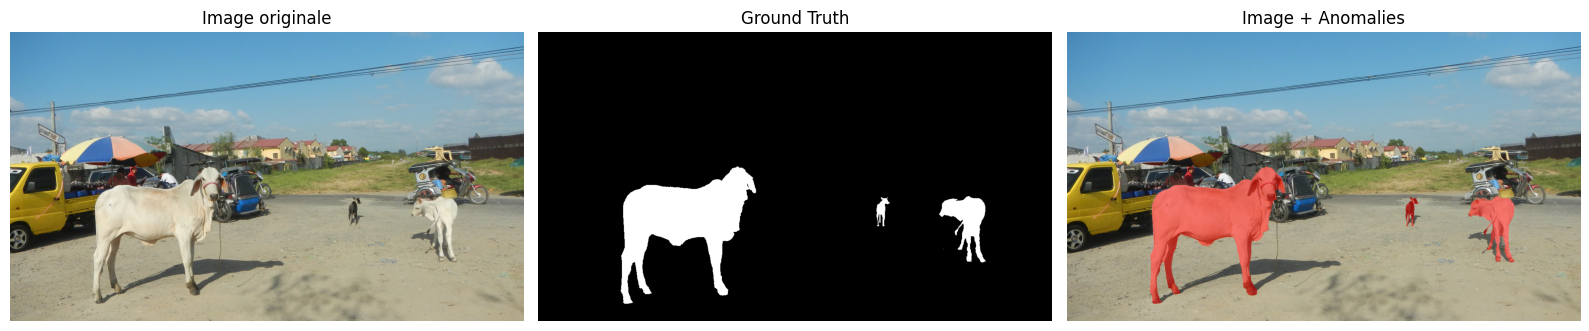

In [5]:

import matplotlib.pyplot as plt

# Choisir une paire image-masque valide
valid = df[df["Mask_exists"] & df["Mask_aligned"]]

if valid.empty:
    raise ValueError("Aucune paire image-masque valide.")

image_path = frames_dir / valid.iloc[0]["Image"]
mask_path = (
    frames_dir / f"{image_path.stem}.labels"
    / "labels_semantic.png"
)

image = np.array(Image.open(image_path).convert("RGB"))
mask = np.array(Image.open(mask_path))

print("Image :", image_path.name)
print("Valeurs du masque :", np.unique(mask))

# Convention RoadAnomaly : classe 2 = anomalie
binary_mask = (mask == 2).astype(np.uint8)

overlay = image.copy()
overlay[binary_mask == 1] = (
    0.5 * image[binary_mask == 1]
    + 0.5 * np.array([255, 0, 0])
).astype(np.uint8)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(image)
axes[0].set_title("Image originale")

axes[1].imshow(binary_mask, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Ground Truth")

axes[2].imshow(overlay)
axes[2].set_title("Image + Anomalies")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


## 4. Class Distribution Analysis

Analyze the distribution of anomalous pixels across images and evaluate class imbalance.

The analysis reveals that anomalous pixels represent approximately **9.85%** of the dataset, compared with **90.15%** for non-anomalous pixels.

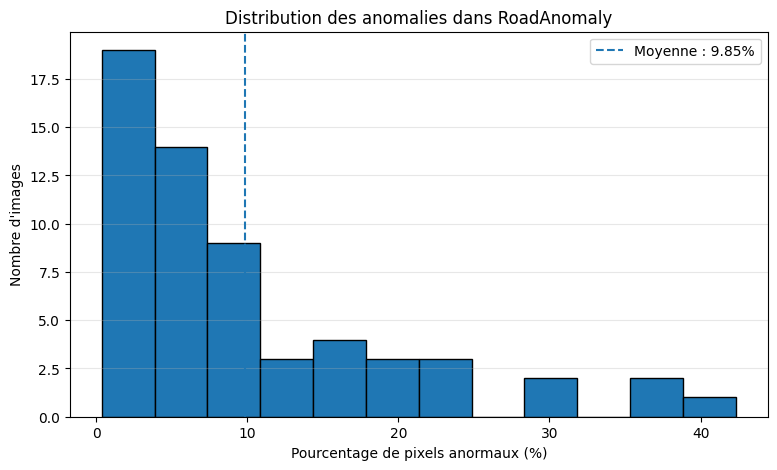

Valeurs rencontrées : [0, 2]


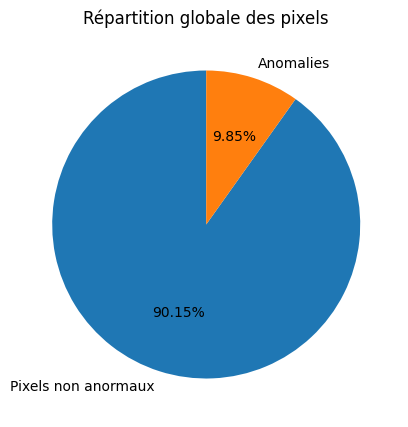

Pixels anormaux : 9.85%
Pixels non anormaux : 90.15%


In [6]:

import matplotlib.pyplot as plt
import numpy as np

# Graphique 1 : distribution des anomalies
plt.figure(figsize=(9, 5))

plt.hist(
    df["Anomaly_%"].dropna(),
    bins=12,
    edgecolor="black"
)

plt.axvline(
    df["Anomaly_%"].mean(),
    linestyle="--",
    label=f"Moyenne : {df['Anomaly_%'].mean():.2f}%"
)

plt.xlabel("Pourcentage de pixels anormaux (%)")
plt.ylabel("Nombre d'images")
plt.title("Distribution des anomalies dans RoadAnomaly")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()

# Graphique 2 : répartition globale des pixels
total_anomaly = 0
total_pixels = 0
all_values = set()

for image_path in images:
    mask_path = (
        frames_dir / f"{image_path.stem}.labels"
        / "labels_semantic.png"
    )

    if mask_path.exists():
        mask = np.array(Image.open(mask_path))
        all_values.update(np.unique(mask).tolist())
        total_anomaly += np.count_nonzero(mask == 2)
        total_pixels += mask.size

print("Valeurs rencontrées :", sorted(all_values))

if not all_values.issubset({0, 2}):
    print("Attention : autres classes à examiner.")

anomaly_pct = 100 * total_anomaly / total_pixels
normal_pct = 100 - anomaly_pct

plt.figure(figsize=(6, 5))
plt.pie(
    [normal_pct, anomaly_pct],
    labels=["Pixels non anormaux", "Anomalies"],
    autopct="%1.2f%%",
    startangle=90
)
plt.title("Répartition globale des pixels")
plt.show()

print(f"Pixels anormaux : {anomaly_pct:.2f}%")
print(f"Pixels non anormaux : {normal_pct:.2f}%")


## 5. Anomaly Category Exploration

Identify the different anomaly categories from image filenames and visualize their distribution.

This analysis helps understand the diversity and representation of road obstacles.

Category
Animals       31
Obstacles     15
Cones          8
Lost tires     3
Vehicles       3
Name: count, dtype: int64


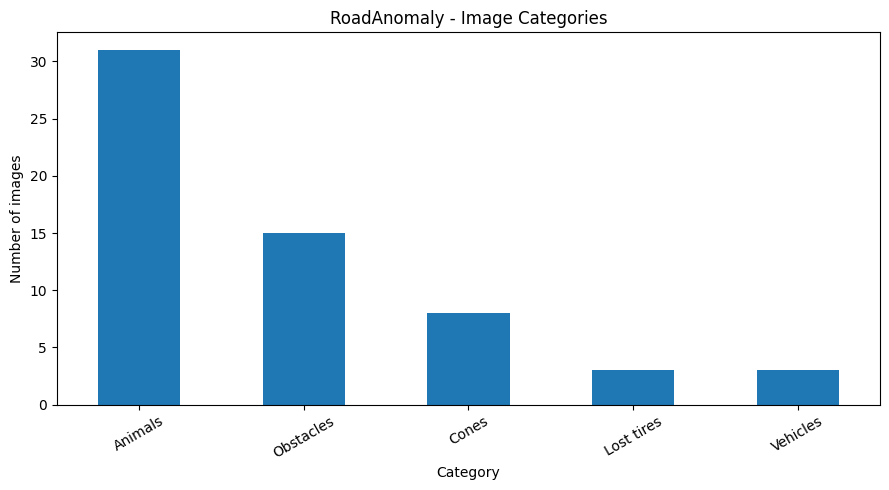

In [9]:

from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt

# Extraire une catégorie indicative du nom du fichier
def get_category(filename):
    name = filename.lower()

    if name.startswith("animals"):
        return "Animals"
    elif name.startswith("cones"):
        return "Cones"
    elif name.startswith("obstacles"):
        return "Obstacles"
    elif name.startswith("vehicle"):
        return "Vehicles"
    elif name.startswith("lost_tires"):
        return "Lost tires"
    else:
        return "Other"

df["Category"] = df["Image"].apply(get_category)

print(df["Category"].value_counts())

df["Category"].value_counts().plot(
    kind="bar",
    figsize=(9, 5),
    title="RoadAnomaly - Image Categories"
)

plt.xlabel("Category")
plt.ylabel("Number of images")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


## 6. Data Quality Assessment

Verify missing masks, image-mask alignment, missing values, and duplicate filenames.

Analyze anomaly coverage statistics to identify potential data quality issues.

In [8]:

print("=== DATA QUALITY REPORT ===")

print("Images analysées :", len(df))

print("Masques manquants :",
      (~df["Mask_exists"]).sum())

print("Masques non alignés :",
      (~df["Mask_aligned"]).sum())

print("Valeurs manquantes :")
print(df.isnull().sum())

print("Noms d'images dupliqués :",
      df["Image"].duplicated().sum())

print("\nStatistiques sur les anomalies :")
print(df["Anomaly_%"].describe())

print("\nImages avec plus de 30 % de pixels anormaux :")
display(df[df["Anomaly_%"] > 30][
    ["Image", "Anomaly_%"]
])


=== DATA QUALITY REPORT ===
Images analysées : 60
Masques manquants : 0
Masques non alignés : 0
Valeurs manquantes :
Image           0
Width           0
Height          0
Mask_exists     0
Mask_aligned    0
Mask_values     0
Anomaly_%       0
Category        0
dtype: int64
Noms d'images dupliqués : 0

Statistiques sur les anomalies :
count    60.000000
mean      9.849561
std      10.059954
min       0.374674
25%       1.801595
50%       6.622938
75%      13.795763
max      42.328559
Name: Anomaly_%, dtype: float64

Images avec plus de 30 % de pixels anormaux :


,Image,Anomaly_%
5,animals06_sheep_roads_lambs.webp,36.845812
8,animals09_working_together.webp,42.328559
15,animals16_Donkeys_of_Morocco.webp,31.175673
23,animals24_Sheep_Herders_Block_the_Road_Kaleyba...,36.716146


## 6.1. Visual Inspection of Multiple Annotations
Review examples from different filename categories to identify incomplete or incorrectly aligned masks.

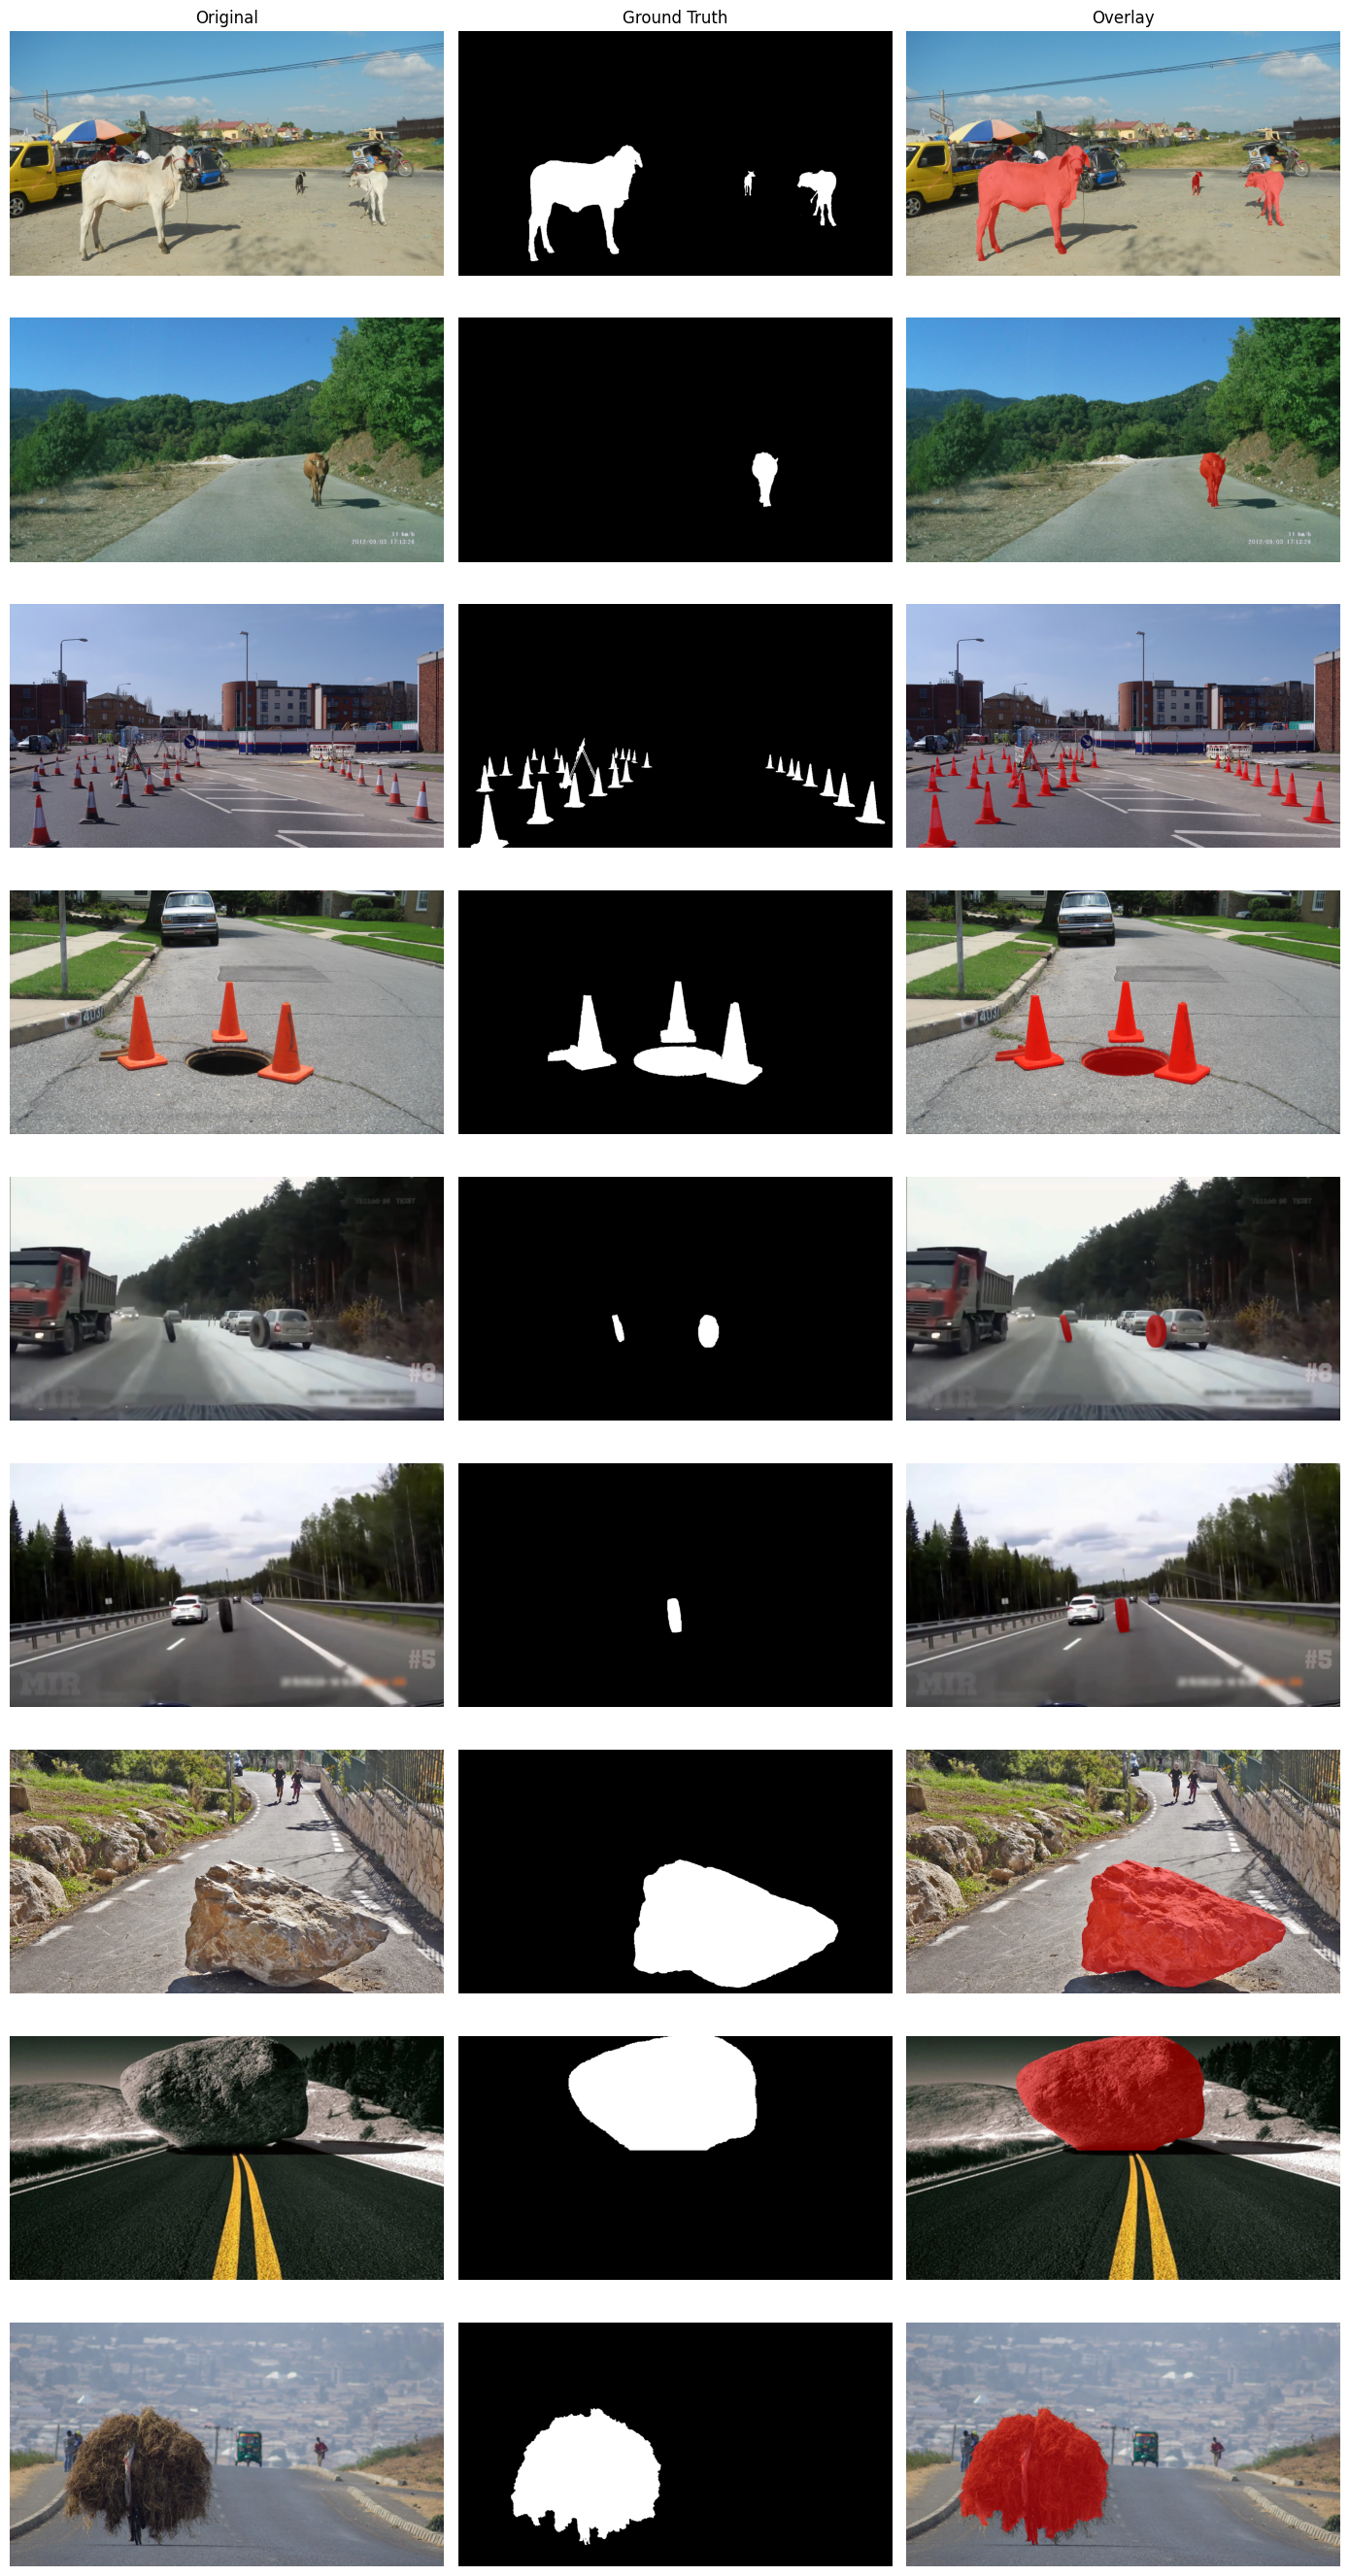

In [10]:
# Up to 9 images, sampling across filename categories
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

valid = df[df["Mask_exists"] & df["Mask_aligned"]].copy()
selected = (valid.groupby("Category", group_keys=False)
            .head(2).head(9))

if selected.empty:
    raise ValueError("No valid image-mask pairs found.")

fig, axes = plt.subplots(len(selected), 3, figsize=(14, 3 * len(selected)), squeeze=False)

for row_i, (_, item) in enumerate(selected.iterrows()):
    image_path = frames_dir / item["Image"]
    mask_path = frames_dir / f"{image_path.stem}.labels" / "labels_semantic.png"
    with Image.open(image_path) as im:
        image = np.array(im.convert("RGB"))
    with Image.open(mask_path) as ms:
        mask = np.array(ms)
    anomaly = mask == 2
    overlay = image.copy()
    overlay[anomaly] = (0.5 * image[anomaly] + 0.5 * np.array([255, 0, 0])).astype(np.uint8)
    for col_i, im in enumerate((image, anomaly, overlay)):
        axes[row_i, col_i].imshow(im, cmap="gray" if col_i == 1 else None)
        axes[row_i, col_i].axis("off")
    axes[row_i, 0].set_ylabel(item["Category"])

for ax, title in zip(axes[0], ("Original", "Ground Truth", "Overlay")):
    ax.set_title(title)
plt.tight_layout()
plt.show()


## 6.2. Exact and Near-Duplicate Check
Identify identical files and flag visually similar images for manual review before creating train/validation/test splits.

In [11]:
import hashlib
from collections import defaultdict
from itertools import combinations

# Exact file duplicates
file_hashes = defaultdict(list)
for p in images:
    file_hashes[hashlib.sha256(p.read_bytes()).hexdigest()].append(p.name)
exact_duplicates = [group for group in file_hashes.values() if len(group) > 1]
print("Exact duplicate groups:", len(exact_duplicates))
for group in exact_duplicates:
    print(group)

# Heuristic perceptual similarity based on 8x8 average hash
def average_hash(path):
    with Image.open(path) as im:
        grayscale = np.asarray(im.convert("L").resize((8, 8)), dtype=float)
    return grayscale > grayscale.mean()

image_hashes = {p.name: average_hash(p) for p in images}
similar_pairs = []
for a, b in combinations(image_hashes, 2):
    distance = int(np.count_nonzero(image_hashes[a] != image_hashes[b]))
    if distance <= 5:
        similar_pairs.append((a, b, distance))

print("Potentially similar pairs:", len(similar_pairs))
for pair in sorted(similar_pairs, key=lambda x: x[2])[:20]:
    print(pair)
print("Note: similarity is a screening heuristic, not proof of duplication.")


Exact duplicate groups: 0
Potentially similar pairs: 0
Note: similarity is a screening heuristic, not proof of duplication.


## 7. Conclusion

- **Dataset:** 60 road images with 60 corresponding segmentation masks.
- **Image resolution:** 1280 × 720 pixels.
- **Data quality:** No missing or misaligned masks detected.
- **Class imbalance:** 90.15% normal pixels vs. 9.85% anomalous pixels.
- **Anomaly variability:** Anomalies occupy between 0.37% and 42.33% of image pixels.
- **Main limitations:** Small dataset size, class imbalance, and risk of overfitting.
- **Next step:** Data Preparation — image resizing, normalization, data augmentation, and train/validation/test splitting.